# [1] 09 Rainfall at Tule Pond and the onset seasonality

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. Seconds.
```

**What this notebook does.**

1. **Daily rain at Tule Pond** from the three nearest NOAA GHCN-daily gauges,
   spliced day by day in the order Fremont > Newark > Hayward Air Terminal (no
   rescaling; the overlaps are documented). The morning-observer COOP gauge
   (Newark) is shifted one day earlier onto the midnight basis, and that shift
   is checked on a storm with a date in the news. Water year Oct 1 to Sep 30,
   named by the year it ends. The gauge files in `Inputs/GHCN_daily` are the
   frozen inputs; they are only downloaded if missing.
2. **Onset seasonality**: every season-resolved onset (the 5 InSAR windows,
   the 9 array windows of 130 d or less) on the water year over the rain
   (Fig 3 bottom).

The forecast of the next event and the rainfall conditioning of the onsets
are notebook 10, which reads the rain table this notebook writes.

Ported from `Hayward_DISP-S1/analysis/run20_precip_ghcn.py` and
`plotting/fig_hrkt_onset_seasonality.py`.

**Outputs** (`outputs/09_rain_seasonality/`): `tulepond_daily_precip.csv`,
`wateryear_totals.csv`, `09_rain_stats.txt`, registry rows `09_*`.

**What to check.** The three gauges agree on water-year totals to ~10 %;
Newark shifted by one day lines up with Hayward on the 11 Dec 2014 storm;
all five InSAR onsets and 9 of the 9 season-resolved array onsets fall between
December and March. The CHECK cell compares the rain tables with the previous
run.

In [1]:
# [2]
import os
import urllib.request
from datetime import datetime

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, forecast_issue_date, params

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

## [3] Paths and parameters

In [2]:
# [4]
notebook = "09_rain_seasonality_v2"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the products of the previous version (09_seasonality_forecast), for the CHECK cell
parity_dir = paths_out["09_seasonality_forecast"]

# the gauges: id -> (short name, order in the composite, day shift for morning-observer COOP gauges).
# Only the three nearest Tule Pond (4, 7 and 18 km); Livermore, San Jose and Oakland Museum (22 to 37 km)
# were carried as alternates until 2026-09-24 and entered no number.
ncei = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{sid}.csv"
stations = {"USC00043244": ("FREMONT", "composite-1", 0),      # COOP but on the midnight basis (checked against Hayward)
            "USC00046144": ("NEWARK", "composite-2", -1),      # COOP, morning observer (checked on the 11 Dec 2014 storm below)
            "USW00093228": ("HAYWARD_AT", "composite-3", 0)}   # ASOS, midnight basis
composite = ["FREMONT", "NEWARK", "HAYWARD_AT"]
tulepond = (37.557, -121.970)      # section centre (lat, lon)
t_start = "1978-10-01"             # start of WY1979 (first HRKT survey 1979.7)
series_end = pd.Timestamp(forecast_issue_date)   # the rain series ends at the forecast issue date so the run reproduces

# the seasonality
resolvable_days = 130      # array windows longer than this do not constrain the season
wet_dowy = (62, 182)       # Dec 1 to Mar 31 as day of water year
density_days, density_max = 7, 80  # the figure: running 7-day total, mm at full colour
x0, x1 = 1979.0, 2026.5           # the time axis of Fig 3: the HRKT record starts 1979.7

# the InSAR stacks at the HGIL and HRKT arrays, saved by notebook 08 for the middle panel of Fig 3
stacks_file = os.path.join(common_paths["out_dir"], "08_alignment_arrays_v2", "aa_insar_stacks.csv")   # -> paths_out["08_alignment_arrays"] after the swap
loma_prieta = 1989.79

events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["08_alignment_arrays"], "hrkt_aa_events.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(events_file, aa_events_file, *[os.path.join(common_paths["ghcn_dir"], f"{sid}.csv") for sid in stations])

Registry for 09_rain_seasonality_v2: run 156f5855, git 349120b+


## [5] Functions: dates and water years

Water year N runs Oct 1 of N-1 to Sep 30 of N; day of water year counts
from Oct 1 = 1.

In [3]:
# [6]
def decyear(dates):
    """Decimal year of a DatetimeIndex, fraction of the actual year length."""
    dates = pd.DatetimeIndex(dates)
    year_start = pd.to_datetime(dates.year.astype(str) + "-01-01")
    next_year_start = pd.to_datetime((dates.year + 1).astype(str) + "-01-01")
    return dates.year + (dates - year_start) / (next_year_start - year_start)


def water_year(dates):
    dates = pd.DatetimeIndex(dates)
    return dates.year + (dates.month >= 10).astype(int)


def dowy(dates):
    """Day of water year: Oct 1 = 1."""
    dates = pd.DatetimeIndex(dates)
    wy_start = pd.to_datetime((water_year(dates) - 1).astype(str) + "-10-01")
    return (dates - wy_start).days + 1


def dowy_frac(decimal_years):
    """Day of water year of a decimal year (365.25-day years, good enough for plotting)."""
    return (((np.asarray(decimal_years) % 1) * 365.25 - 274) % 365.25) + 1

## [7] The daily rain composite

One value per day: the first gauge that reported, in the order Fremont >
Newark > Hayward Air Terminal. The water-year totals table records which
gauges made each year and how many days are missing.

In [4]:
# [8]
def fetch(sid):
    """One GHCN-daily gauge as a daily series (mm) from t_start, with its metadata; downloaded once if missing."""
    path = os.path.join(common_paths["ghcn_dir"], f"{sid}.csv")
    if not os.path.exists(path) or os.path.getsize(path) < 1000:
        print("downloading", sid)
        urllib.request.urlretrieve(ncei.format(sid=sid), path)
    table = pd.read_csv(path, usecols=["DATE", "LATITUDE", "LONGITUDE", "NAME", "PRCP"], low_memory=False)
    table["DATE"] = pd.to_datetime(table.DATE)
    table = table[table.DATE >= t_start]
    info = dict(name=table.NAME.iloc[0], lat=float(table.LATITUDE.iloc[0]), lon=float(table.LONGITUDE.iloc[0]),
                first=table.DATE.min().date(), last=table.DATE.max().date())
    series = table.set_index("DATE").PRCP / 10.0          # tenths of mm -> mm
    series = series[~series.index.duplicated()]
    if stations[sid][2]:
        series.index = series.index + pd.Timedelta(days=stations[sid][2])      # the COOP morning-observer shift
    return series, info


days = pd.date_range(t_start, series_end, freq="D")
rain = pd.DataFrame(index=days)
gauge_info = {}
for sid, (name, role, shift) in stations.items():
    series, info = fetch(sid)
    rain[name] = series.reindex(days)
    gauge_info[name] = dict(sid=sid, role=role, shift=shift, **info, n_valid=int(series[series.index <= series_end].notna().sum()),
                            dist_km=np.hypot((info["lat"] - tulepond[0]) * 111.19,
                                             (info["lon"] - tulepond[1]) * 111.19 * np.cos(np.radians(tulepond[0]))))
# the composite: the first gauge in the order that reported that day
rain["prcp_mm"] = np.nan
rain["src"] = "none"
for name in composite:
    take = rain.prcp_mm.isna() & rain[name].notna()
    rain.loc[take, "prcp_mm"] = rain.loc[take, name]
    rain.loc[take, "src"] = name
rain["decyear"] = decyear(rain.index)
rain["wy"] = water_year(rain.index)
rain["dowy"] = dowy(rain.index)
rain.index.name = "date"

# water-year totals, per gauge and for the composite
by_wy = rain.groupby("wy")
wy_totals = pd.DataFrame({"total_mm": by_wy.prcp_mm.sum(min_count=1), "n_days": by_wy.prcp_mm.count(),
                          "n_missing": by_wy.prcp_mm.apply(lambda x: x.isna().sum()), "max_day_mm": by_wy.prcp_mm.max(),
                          "src": by_wy.src.agg(lambda x: "+".join(sorted(set(x) - {"none"})))})
for name in [v[0] for v in stations.values()]:
    wy_totals[f"{name}_mm"] = by_wy[name].sum(min_count=1)
    wy_totals[f"{name}_ndays"] = by_wy[name].count()
wy_totals["complete"] = wy_totals.n_missing <= 20
rain.to_csv(os.path.join(out_dir, "tulepond_daily_precip.csv"), float_format="%.4f")
wy_totals.to_csv(os.path.join(out_dir, "wateryear_totals.csv"), float_format="%.1f")

stats_lines = ["09 RAIN AND SEASONALITY",
               f"rain series {days[0].date()} to {days[-1].date()} (ends at the pinned forecast issue date {forecast_issue_date})", "stations:"]
for name, info in gauge_info.items():
    stats_lines.append(f"  {name:<12} {info['sid']}  {info['name']:<38} {info['dist_km']:5.1f} km  {info['first']}..{info['last']}  "
                       f"n={info['n_valid']}  [{info['role']}, day shift {info['shift']:+d}]")
n_by_source = rain.src.value_counts()
stats_lines.append("composite = first reporting gauge in the order " + " > ".join(composite) + ": " +
                   ", ".join(f"{k} {v} d" for k, v in n_by_source.items()))
# how the three gauges agree where they overlap
for gauge_a, gauge_b in [("FREMONT", "NEWARK"), ("FREMONT", "HAYWARD_AT"), ("NEWARK", "HAYWARD_AT")]:
    both_complete = wy_totals[(wy_totals[f"{gauge_a}_ndays"] >= 350) & (wy_totals[f"{gauge_b}_ndays"] >= 350)]
    ratio = both_complete[f"{gauge_a}_mm"] / both_complete[f"{gauge_b}_mm"]
    overlap = rain[[gauge_a, gauge_b]].dropna()
    overlap = overlap[overlap.index.isin(rain.index[rain.wy.isin(both_complete.index)])]
    storm_days_both = overlap[(overlap[gauge_a] >= 10) | (overlap[gauge_b] >= 10)]
    r_day = np.corrcoef(storm_days_both[gauge_a], storm_days_both[gauge_b])[0, 1] if len(storm_days_both) > 10 else np.nan
    stats_lines.append(f"  {gauge_a}/{gauge_b}: {len(both_complete)} complete WYs, WY-total ratio median {ratio.median():.2f} "
                       f"(range {ratio.min():.2f}-{ratio.max():.2f}); same-day totals on days >= 10 mm: n={len(storm_days_both)}, r={r_day:.2f}")
complete_years = wy_totals[wy_totals.complete & (wy_totals.index >= 1980) & (wy_totals.index <= 2025)]
stats_lines.append(f"WY1980-2025 complete years (n={len(complete_years)}): median {complete_years.total_mm.median():.0f} mm, "
                   f"10-90% {complete_years.total_mm.quantile(.1):.0f}-{complete_years.total_mm.quantile(.9):.0f} mm")
print("\n".join(stats_lines))

09 RAIN AND SEASONALITY
rain series 1978-10-01 to 2026-08-25 (ends at the pinned forecast issue date 2026-08-25)
stations:
  FREMONT      USC00043244  FREMONT, CA US                           4.4 km  1996-06-01..2026-08-21  n=10673  [composite-1, day shift +0]
  NEWARK       USC00046144  NEWARK, CA US                            7.2 km  1978-10-01..2021-01-15  n=15062  [composite-2, day shift -1]
  HAYWARD_AT   USW00093228  HAYWARD AIR TERMINAL, CA US             17.5 km  1998-09-19..2026-08-21  n=10191  [composite-3, day shift +0]
composite = first reporting gauge in the order FREMONT > NEWARK > HAYWARD_AT: FREMONT 10673 d, NEWARK 6724 d, HAYWARD_AT 69 d, none 30 d
  FREMONT/NEWARK: 16 complete WYs, WY-total ratio median 1.12 (range 0.73-1.29); same-day totals on days >= 10 mm: n=321, r=0.10
  FREMONT/HAYWARD_AT: 21 complete WYs, WY-total ratio median 0.93 (range 0.72-1.45); same-day totals on days >= 10 mm: n=384, r=0.41
  NEWARK/HAYWARD_AT: 19 complete WYs, WY-total ratio median 0.86

## [9] CHECK: the COOP observation-time shift

Newark's observer reads the gauge in the morning, so a storm is booked on
the day after it fell. Shifted one day earlier it should agree with Hayward
Air Terminal (a midnight-basis ASOS gauge) on storm days, and not before.
Then one storm with a date in the news: the "storm of the decade", Thursday
11 December 2014.

In [5]:
# [10]
newark_as_published, _ = fetch("USC00046144")
newark_as_published.index = newark_as_published.index + pd.Timedelta(days=1)          # undo the shift
hayward = rain["HAYWARD_AT"]
for label, series in (("as published", newark_as_published), ("shifted -1 d", rain["NEWARK"])):
    both = pd.concat([series.reindex(days), hayward], axis=1).dropna()
    both = both[(both.iloc[:, 0] >= 10) | (both.iloc[:, 1] >= 10)]
    print(f"Newark vs Hayward on storm days, {label}: r = {np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1]:.2f} (n = {len(both)})")

# Hayward books the storm on the 11th; Newark as published on the 12th (the morning its observer read the gauge),
# on the 11th once shifted. Fremont, unshifted, also puts most of it on the 11th.
storm = pd.date_range("2014-12-10", "2014-12-12")
storm_table = pd.DataFrame({"Newark as published": newark_as_published.reindex(storm),
                            "Newark shifted -1 d": rain["NEWARK"].reindex(storm),
                            "Hayward AT (midnight)": hayward.reindex(storm),
                            "Fremont (no shift)": rain["FREMONT"].reindex(storm)}, index=storm.strftime("%a %d %b %Y"))
print("\nthe 11 Dec 2014 storm, mm per day:")
print(storm_table.round(1).to_string())

Newark vs Hayward on storm days, as published: r = -0.24 (n = 413)
Newark vs Hayward on storm days, shifted -1 d: r = 0.44 (n = 361)

the 11 Dec 2014 storm, mm per day:
                 Newark as published  Newark shifted -1 d  Hayward AT (midnight)  Fremont (no shift)
Wed 10 Dec 2014                  0.0                  1.3                    0.0                 0.0
Thu 11 Dec 2014                  1.3                 92.5                   83.3                53.3
Fri 12 Dec 2014                 92.5                  2.0                    4.1                27.9


## [11] The event catalogues

InSAR events from 04, and the HRKT array events from 08 whose survey windows
(130 d or less, the dense era) resolve the season.

In [6]:
# [12]
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"].sort_values("onset_yr").reset_index(drop=True)
aa_events = pd.read_csv(aa_events_file)
aa_dense = aa_events[aa_events.window_days <= resolvable_days].reset_index(drop=True)
print(f"InSAR {len(insar_events)} events; array dense era {len(aa_dense)} events (windows <= {resolvable_days} d)")


def n_dec_to_mar(catalogue):
    """How many onsets fall between Dec 1 and Mar 31 (by midpoint)."""
    day = dowy_frac(catalogue.onset_yr)
    return int(((day >= wet_dowy[0]) & (day <= wet_dowy[1])).sum())

InSAR 5 events; array dense era 9 events (windows <= 130 d)


## [13] Figure 3 (bottom): onsets on the water year over the rain

Each water year is a column filled with the running 7-day rain total; the
water year runs down the page from Oct 1. Onsets are bars bounding the
observation window only, no midpoint marker: the event is equally likely
anywhere inside its window. Annual-survey array detections (windows of 300
to 390 d) are omitted because they do not constrain the season.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-22/fig3b_onset_seasonality_wateryear_density7d_vmax80mm.png


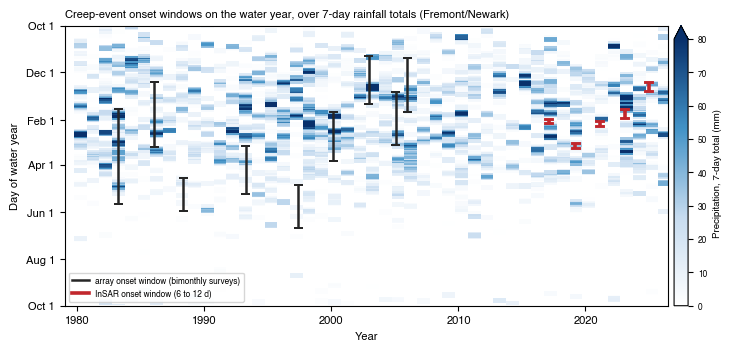

array resolvable: 9 (6 Dec-Mar); InSAR: 5 (5 Dec-Mar)


In [7]:
# [14]
def onset_bar(ax, x, day_lo, day_hi, color, lw):
    """A vertical bar from day_lo to day_hi of the water year at x, wrapping across Oct 1 if needed."""
    segments = [(day_lo, day_hi)] if day_hi >= day_lo else [(day_lo, 366), (1, day_hi)]
    for a, b in segments:
        ax.plot([x, x], [a, b], "-", color=color, lw=lw, solid_capstyle="butt", zorder=5)
    for y in (day_lo, day_hi):
        ax.plot([x - 0.28, x + 0.28], [y, y], "-", color=color, lw=lw * 0.8, zorder=5)


utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, ax = plt.subplots(figsize=(7.2, 3.4), constrained_layout=True)
rain_plot = rain[(rain.wy >= int(np.floor(x0)) + 1) & (rain.wy <= int(np.ceil(x1)))]
rain_7d = rain_plot.prcp_mm.fillna(0).rolling(density_days, min_periods=1).sum()
water_years = sorted(rain_plot.wy.unique())
rain_grid = np.full((367, len(water_years)), np.nan)          # day of water year x water year
x_edges = []
for j, wy in enumerate(water_years):
    this_year = rain_plot[rain_plot.wy == wy]
    rain_grid[this_year.dowy.values, j] = rain_7d[this_year.index].values
    x_edges.append(wy - 1 + 273 / 365.25)
x_edges.append(water_years[-1] + 273 / 365.25)
cmap = LinearSegmentedColormap.from_list("rain", ["#FFFFFF", "#C6DBEF", "#4292C6", "#08306B"])
mesh = ax.pcolormesh(np.array(x_edges), np.arange(-0.5, 367.5), rain_grid, cmap=cmap, vmin=0, vmax=density_max, shading="flat", rasterized=True, zorder=0)
for event in aa_dense.itertuples():
    onset_bar(ax, event.onset_yr, dowy_frac(event.onset_lo), dowy_frac(event.onset_hi), "0.15", 1.8)
for event in insar_events.itertuples():
    onset_bar(ax, event.onset_yr, dowy_frac(event.onset_lo), dowy_frac(event.onset_hi), "#C1272D", 2.6)
ax.set_xlim(x0, x1)
ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366])
ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year")
ax.set_ylabel("Day of water year")
cb = fig.colorbar(mesh, ax=ax, pad=0.01, fraction=0.03, extend="max")
cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=7)
cb.ax.tick_params(labelsize=6)
ax.legend(handles=[Line2D([], [], color="0.15", lw=1.8, label="array onset window (bimonthly surveys)"),
                   Line2D([], [], color="#C1272D", lw=2.6, label="InSAR onset window (6 to 12 d)")], fontsize=6, loc="lower left")
ax.set_title("Creep-event onset windows on the water year, over 7-day rainfall totals (Fremont/Newark)", loc="left", fontsize=8)
f_season = os.path.join(fig_dir, f"fig3b_onset_seasonality_wateryear_density{density_days}d_vmax{density_max}mm.png")
fig.savefig(f_season, dpi=300)
fig.savefig(f_season.replace(".png", ".pdf"))
print("Saved figure to:", f_season)
plt.show()
print(f"array resolvable: {len(aa_dense)} ({n_dec_to_mar(aa_dense)} Dec-Mar); InSAR: {len(insar_events)} ({n_dec_to_mar(insar_events)} Dec-Mar)")

## [15] Figure 3: the 45-year history at Tule Pond and the onsets on the water year

One time axis, three panels. a) The survey cadence of the two arrays that
span the section. b) The HRKT record with the dense-era detections shaded (08;
the annual-survey years after 2006 are unobserved by the detector and greyed),
the InSAR fault-parallel stack tied to it, the InSAR onsets dashed, and the
two arrays since 2015 as insets. c) The onset windows on the water year over
the 7-day rain totals (the panel above), so the reader sees the clock and
the season in one look.

bimonthly surveys at HRKT end 2007.44; annual surveys from then until the InSAR record starts 2016.67


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved Fig 3 to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-22/fig3_history_rain_ap30-150m_coh0.7_mp5_sw200m_density7d.png


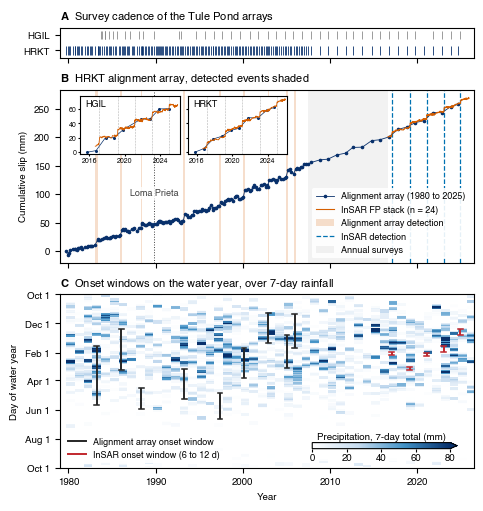

In [8]:
# [16]
aa_stacks = pd.read_csv(stacks_file)
stacks = {code: aa_stacks[aa_stacks.code == code] for code in ("HGIL", "HRKT")}
hrkt = utils.load_aa(common_paths["aa_dir"], "HRKT")
hgil = utils.load_aa(common_paths["aa_dir"], "HGIL")
aa_color, insar_color, det_color = "#08306B", "#D55E00", "#0072B2"

# sized for a 1.5-column slot (12.0 cm wide, 0.65 of the Science text width); fonts stay at 7-8 pt at that size
fig, axes = plt.subplots(3, 1, figsize=(4.72, 5.0), sharex=True, height_ratios=[0.28, 1.6, 1.6], constrained_layout=True)     # B and C the same height
label_pt = 7                                     # axis titles the same size as the tick labels
for ax in axes:
    ax.tick_params(labelsize=label_pt)

# a) survey cadence
ax = axes[0]
ax.eventplot([hgil.year.values, hrkt.year.values], lineoffsets=[1, 0], linelengths=0.55, colors=["0.55", aa_color], lw=0.6)
ax.set_yticks([1, 0])
ax.set_yticklabels(["HGIL", "HRKT"])
ax.set_ylim(-0.5, 1.5)
ax.set_title(r"$\bf{A}$  Survey cadence of the Tule Pond arrays", loc="left", fontsize=8)

# b) the HRKT record: the dense-era detections shaded, the unobserved annual-survey years greyed, the InSAR onsets dashed
ax = axes[1]
hrkt_stack = stacks["HRKT"]
ax.plot(hrkt.year, hrkt.cum_mm, "o", ms=1.6, color=aa_color, lw=0.6, ls="-", zorder=3,
        label=f"Alignment array ({hrkt.year.min():.0f} to {hrkt.year.max():.0f})")
ax.plot(hrkt_stack.date, hrkt_stack.slip_mm, "-", lw=0.8, color=insar_color, zorder=5, label=f"InSAR FP stack (n = {int(hrkt_stack.n_crossings.iloc[0])})")      # shifted onto the array datum (caption)
# only the dense-era detections, the ones the forecast uses; the annual-survey years after them are unobserved by
# the clock's standard, so the section is greyed until the first InSAR detection (Dani, 2026-09-24)
for event in aa_dense.itertuples():
    ax.axvspan(event.onset_lo, event.onset_hi, color=insar_color, alpha=0.20, lw=0, zorder=1,
               label="Alignment array detection" if event.Index == 0 else None)
# the grey starts where the bimonthly surveys end: the last HRKT survey after which every gap to the next survey
# is longer than resolvable_days (130 d, the window the seasonality needs); the arrays were then surveyed annually
survey_gap_days = np.diff(hrkt.year.values) * 365.25
dense_era_end = float(hrkt.year.values[np.max(np.where(survey_gap_days <= resolvable_days)[0]) + 1])
insar_start = float(hrkt_stack.date.min())                       # from here the InSAR samples every 6 to 12 d
print(f"bimonthly surveys at HRKT end {dense_era_end:.2f}; annual surveys from then until the InSAR record starts {insar_start:.2f}")
ax.axvspan(dense_era_end, insar_start, color="0.5", alpha=0.10, lw=0, zorder=0, label="Annual surveys")
for i, onset in enumerate(insar_events.onset_yr):
    ax.axvline(onset, color=det_color, lw=0.9, ls="--", zorder=2, label="InSAR detection" if i == 0 else None)
ax.axvline(loma_prieta, color="0.25", lw=0.7, ls=":", zorder=2)
ax.text(loma_prieta, 0.43, "Loma Prieta", transform=ax.get_xaxis_transform(), fontsize=6.5, color="0.25", ha="center", va="top",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1))   # below the insets, above the curve
ax.set_ylabel("Cumulative slip (mm)", fontsize=label_pt)
handles, labels = ax.get_legend_handles_labels()
order = [i for i, label in enumerate(labels) if label != "Annual surveys"] + [labels.index("Annual surveys")]     # the grey last
ax.legend([handles[i] for i in order], [labels[i] for i in order], fontsize=6.5, loc="lower right", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(r"$\bf{B}$  HRKT alignment array, detected events shaded", loc="left", fontsize=8)
# the two arrays since 2015 as insets, each zeroed at its first survey, on one y range
zoom_t0 = 2015.0
zoom = {}
for code, array in (("HGIL", hgil), ("HRKT", hrkt)):
    recent = array[array.year >= zoom_t0]
    zoom[code] = (recent, stacks[code], float(recent.cum_mm.iloc[0]))
zoom_hi = max(max(float(stack.slip_mm.max()), float(recent.cum_mm.max())) - zero for recent, stack, zero in zoom.values())
for i, code in enumerate(("HGIL", "HRKT")):
    recent, stack, zero = zoom[code]
    inset = ax.inset_axes([0.05 + 0.26 * i, 0.63, 0.24, 0.33])      # above the array curve, which reaches the insets' height only after 2010
    inset.plot(recent.year, recent.cum_mm - zero, "o", ms=1.2, color=aa_color, lw=0.5, ls="-")
    inset.plot(stack.date, stack.slip_mm - zero, "-", lw=0.6, color=insar_color)
    for onset in insar_events.onset_yr:
        inset.axvline(onset, color="0.7", lw=0.4, ls="--", zorder=0)
    inset.set_xlim(zoom_t0, 2026.2)
    inset.set_ylim(-2, zoom_hi + 3)
    inset.set_xticks([2016, 2020, 2024])
    inset.tick_params(labelsize=5, length=1.5, pad=1.5)      # small on purpose: the insets must not distract
    if i == 1:
        inset.set_yticklabels([])
    inset.text(0.05, 0.95, code, transform=inset.transAxes, fontsize=6.5, va="top")

# c) the onset windows on the water year over the rain (the grid of the figure above)
ax = axes[2]
mesh = ax.pcolormesh(np.array(x_edges), np.arange(-0.5, 367.5), rain_grid, cmap=cmap, vmin=0, vmax=density_max, shading="flat", rasterized=True, zorder=0)
for event in aa_dense.itertuples():
    onset_bar(ax, event.onset_yr, dowy_frac(event.onset_lo), dowy_frac(event.onset_hi), "0.15", 1.4)
for event in insar_events.itertuples():
    onset_bar(ax, event.onset_yr, dowy_frac(event.onset_lo), dowy_frac(event.onset_hi), "#C1272D", 1.4)
ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366])
ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year", fontsize=label_pt)
ax.set_ylabel("Day of water year", fontsize=label_pt)
# the colour bar horizontal inside the panel at the bottom right (the summer is empty), on a white backing
ax.add_patch(plt.Rectangle((0.575, 0.04), 0.415, 0.24, transform=ax.transAxes, facecolor="white", edgecolor="none", alpha=0.85, zorder=4))
cax = ax.inset_axes([0.61, 0.11, 0.35, 0.035])
cb = fig.colorbar(mesh, cax=cax, orientation="horizontal", extend="max")
cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=label_pt, labelpad=2)
cb.ax.xaxis.set_label_position("top")
cb.ax.tick_params(labelsize=label_pt, length=2, pad=1.5)
ax.legend(handles=[Line2D([], [], color="0.15", lw=1.4, label="Alignment array onset window"),
                   Line2D([], [], color="#C1272D", lw=1.4, label="InSAR onset window (6 to 12 d)")], fontsize=6.5, loc="lower left",
          frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(r"$\bf{C}$  Onset windows on the water year, over 7-day rainfall", loc="left", fontsize=8)
ax.set_xlim(x0, x1)
f_fig3 = os.path.join(fig_dir, f"fig3_history_rain_{params}_density{density_days}d.png")
fig.savefig(f_fig3, dpi=300)
fig.savefig(f_fig3.replace(".png", ".pdf"))
print("Saved Fig 3 to:", f_fig3)
plt.show()

## [17] CHECK: the same as the previous version

The previous version also carried three far gauges as extra columns; the
composite and every number are unchanged, so the shared columns must match.

In [9]:
# [18]
for name in ("tulepond_daily_precip.csv", "wateryear_totals.csv"):
    old_path = os.path.join(parity_dir, name)
    if not os.path.exists(old_path):
        print(f"no previous {name}; check skipped")
        continue
    new, old = pd.read_csv(os.path.join(out_dir, name)), pd.read_csv(old_path)
    old = old[new.columns]
    assert new.shape == old.shape, f"{name}: layout differs"
    numeric = new.select_dtypes("number").columns
    assert new.drop(columns=numeric).fillna("").equals(old.drop(columns=numeric).fillna("")), f"{name}: text columns differ"
    assert np.array_equal(np.isnan(new[numeric].values.astype(float)), np.isnan(old[numeric].values.astype(float))), f"{name}: NaN pattern differs"
    diff = np.nanmax(np.abs(new[numeric].values.astype(float) - old[numeric].values.astype(float)))
    print(f"{name}: same {new.shape} (shared columns), max |difference| {diff:.2e}")
    assert diff < 1e-9, f"{name} differs from the previous version"

tulepond_daily_precip.csv: same (17496, 9) (shared columns), max |difference| 0.00e+00
wateryear_totals.csv: same (48, 13) (shared columns), max |difference| 0.00e+00


## [19] REGISTER

In [10]:
# [20]
stats_lines += ["", f"season-resolved onsets: array {len(aa_dense)} ({n_dec_to_mar(aa_dense)} Dec-Mar), InSAR {len(insar_events)} ({n_dec_to_mar(insar_events)} Dec-Mar)"]
sidecar = REG.sidecar("09_rain", stats_lines)
REG.register("09_rain_series_start", str(days[0].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_rain_series_end", str(days[-1].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_wy_median_mm", complete_years.total_mm.median(), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_wy_p10_mm", complete_years.total_mm.quantile(.1), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_wy_p90_mm", complete_years.total_mm.quantile(.9), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_n_aa_season_resolved", len(aa_dense), "count", 0, where="Fig3 caption", cell="catalogues", sidecar=sidecar)
REG.register("09_n_aa_dec_mar", n_dec_to_mar(aa_dense), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("09_n_insar_dec_mar", n_dec_to_mar(insar_events), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/09_rain_seasonality_v2/09_rain_stats.txt
  registered 09_rain_series_start = 1978-10-01 date  -> M9
  registered 09_rain_series_end = 2026-08-25 date  -> M9
  registered 09_wy_median_mm = 362 mm  -> M9
  registered 09_wy_p10_mm = 219 mm  -> M9


  registered 09_wy_p90_mm = 567 mm  -> M9
  registered 09_n_aa_season_resolved = 9 count  -> Fig3 caption


  registered 09_n_aa_dec_mar = 6 count  -> P10
  registered 09_n_insar_dec_mar = 5 count  -> P10
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'